# Assignment 2: Data Preparation
### COMM 4259 <br> <i>Foundations of Machine Learning and AI with Python</i>

© Jingjing Li- Ask for permission for using/quoting: jingjing.li@virginia.edu


# Description

This assignment has 3 sections and is to be completed individually. Collaborations with peers or seeking assistance from unauthorized sources will be considered a breach of the Honor Code.

| Section | What | Weight | Generative AI |
|---|---|---|---|
| 1 | Explore the Customer Churn data | 35% | Not allowed |
| 2 | Data preparation decisions, a workbench app, evaluation and findings | 55% | 2A, 2C.1 and 2C.3 not allowed; 2B and 2C.2 use Claude Code |
| 3 | GitHub record of your work | 10% | Not needed |

- **Restricted resources**: <font color='red'>Section 1, Part 2A, 2C.1 and 2C.3: DO NOT use any generative AI tools. Finish Section 1 and 2A before you start 2B.</font>
- **Recommended resources**: the Lab 3, 5 and 6 notebooks and your notes.

## Submission
- **Canvas**: upload this notebook, with your GitHub repository link filled in below.
- **GitHub**: push your work to your `comm4259-work` repository before the deadline (see the GitHub section).

**GitHub repository link:** *(paste it here, for example https://github.com/your-username/comm4259-work)*

**Due: 11:59 PM on Sunday, October 25.**

# Section 1: Explore the Customer Churn Data (35%, no generative AI)
Answer the following questions through exploratory data analysis (for example groupby, sort_values, loc), without generative AI. You can use Labs 5 and 6 as a reference. There are three questions: state spending (12 points), the month with the most registrations and its line plot (12 points), and mothers versus fathers (11 points).

## Import libraries

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

<div class="alert alert-warning">
You can watch this <a href ="https://www.youtube.com/watch?v=qy0fDqoMJx8&list=PL5-da3qGB5ICCsgW1MxlZ0Hq8LL5U3u9y&index=14"> video</a> to learn more about the groupby() function.    
</div>

## Read the customer dataset

In [2]:
customer = pd.read_csv("CustomerChurn_cleaned.csv")

print(customer.shape)

print(customer.dtypes)

customer.head()

(970, 23)
CustomerID              int64
City                      str
State                     str
PostalCode              int64
CountryCode               str
FlagMailable              str
FlagEmailable             str
CustomerSinceDate         str
IncomeDescription       int64
NetWorth                int64
Education                 str
Gender                    str
BirthYear             float64
PresenceOfChildren      int64
Churn                     str
Orders_count          float64
TotalSales_sum        float64
ShippingCharge_sum    float64
CustomerSinceYear       int64
CustomerSinceMonth      int64
CustomerSinceDay        int64
CustomerSinceTime         str
CustomerSinceHour       int64
dtype: object


,CustomerID,City,State,PostalCode,CountryCode,FlagMailable,FlagEmailable,CustomerSinceDate,IncomeDescription,NetWorth,...,PresenceOfChildren,Churn,Orders_count,TotalSales_sum,ShippingCharge_sum,CustomerSinceYear,CustomerSinceMonth,CustomerSinceDay,CustomerSinceTime,CustomerSinceHour
0,50000669,Gunnison,CO,81230,US,Y,N,2012-01-03 16:36:00,8,10,...,2,NotRetained,1.0,29.95,10.00,2012,1,3,16:36:00,16
1,50000785,Stayton,OR,97383,US,N,N,2012-01-03 18:21:00,14,1,...,2,NotRetained,1.0,14.95,5.00,2012,1,3,18:21:00,18
2,50002315,Chicago,IL,60613,US,Y,Y,2012-01-04 07:55:00,6,6,...,2,Retained,13.0,1543.75,140.00,2012,1,4,07:55:00,7
3,50002393,Sacramento,CA,95816,US,Y,N,2012-01-04 10:49:00,7,9,...,2,Retained,7.0,682.94,20.99,2012,1,4,10:49:00,10
4,50003221,Paisley,FL,32767,US,Y,N,2012-01-04 16:39:00,2,4,...,2,NotRetained,1.0,44.95,5.00,2012,1,4,16:39:00,16


## Which state's customers spend the most? (12 points)
The code is given. Run it, then answer the three questions in the cell after it.

In [6]:
# Total, average and number of customers' spending (TotalSales_sum) for each state
state_sales = customer.groupby("State").TotalSales_sum.agg(["sum", "mean", "count"])
state_sales.sort_values("mean", ascending=False).head()

,sum,mean,count
State,,,
AK,2123.47,424.694000,5
NE,379.45,379.450000,1
MI,11623.24,374.943226,31
MO,6369.19,303.294762,21
WI,5326.87,295.937222,18


Answer here:
1. In your own words, what do `agg(["sum", "mean", "count"])` and `sort_values("sum", ascending=False)` do?

-These functions aggregate columns for sum, mean, and count and then sort_values sorts them based on the new sum column in descending order. 

2. Which state's customers spend the most in total?

-California

3. Change `"sum"` to `"mean"` in the last line and run the cell again. Does the answer change, and which measure would you report to a manager?

-Yes it changes to Alaska. I would keep it on sum because Alaska doesn't have much data and appears to be insignificant.

## Which month has the most registrations? (12 points, with the line plot below)
Replace `"COLUMN_NAME"` with the column that holds the month a customer registered (look at the column names printed above), then run the cell.

In [5]:
# Replace "COLUMN_NAME" with the month column, then run the cell
customer.groupby("CustomerSinceMonth").CustomerID.count().sort_values(ascending=False).head()

CustomerSinceMonth
1    93
8    92
3    91
5    91
6    86
Name: CustomerID, dtype: int64

Write down your observations here:
Month 1

## Use a lineplot to show customer registrations by month.
Replace both `"COLUMN_NAME"`s with the same month column. `reset_index()` turns the groupby result into a dataframe that the plot can use.

<Axes: xlabel='CustomerSinceMonth', ylabel='CustomerID'>

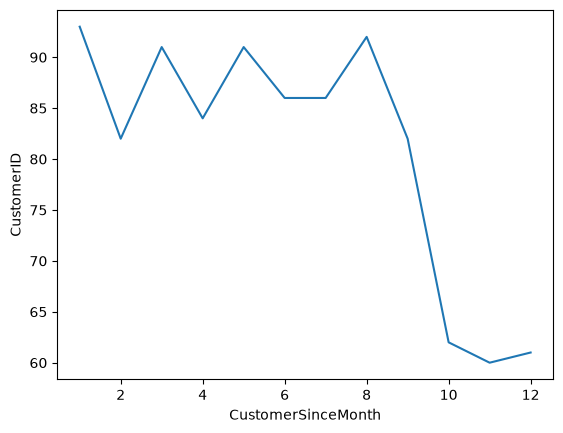

In [7]:
# Replace both "COLUMN_NAME"s with the same month column, then run the cell
month_count = customer.groupby("CustomerSinceMonth").CustomerID.count().reset_index()
sns.lineplot(x="CustomerSinceMonth", y="CustomerID", data=month_count)

Write down your observation here:

-There appears to be less sign ups later in the year

## Do mothers on average place more orders than fathers? (11 points)
```Hint: Group by the dataframe via two columns (Gender and PresenceOfChildren) and find the average count of orders (Orders_count). ```
<br>
```Use a catplot to visualize the results. You can search online for detailed usage sns.catplot(x =, y = , hue = , data = , kind = "point")```

Sex     Pclass
female  1         106.1
        2          22.0
        3          16.1
male    1          67.2
        2          19.7
        3          12.7
Name: Fare, dtype: float64


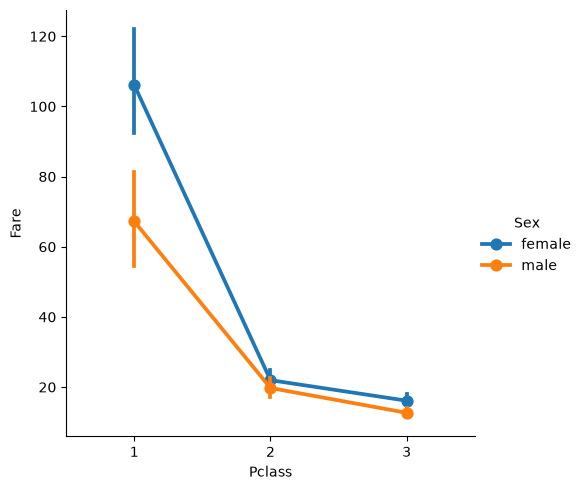

In [8]:
# SAMPLE (Titanic data, not the Customer data): group by TWO columns, then plot the averages with a catplot.
# Each row of the output is one combination, for example women in first class paid 106.1 on average and men 67.2.
# Adapt the pattern to the question above, in the empty cell below.
titanic_sample = pd.read_csv("titanic_train.csv")
print(titanic_sample.groupby(["Sex", "Pclass"]).Fare.mean().round(1))
sns.catplot(x="Pclass", y="Fare", hue="Sex", data=titanic_sample, kind="point")

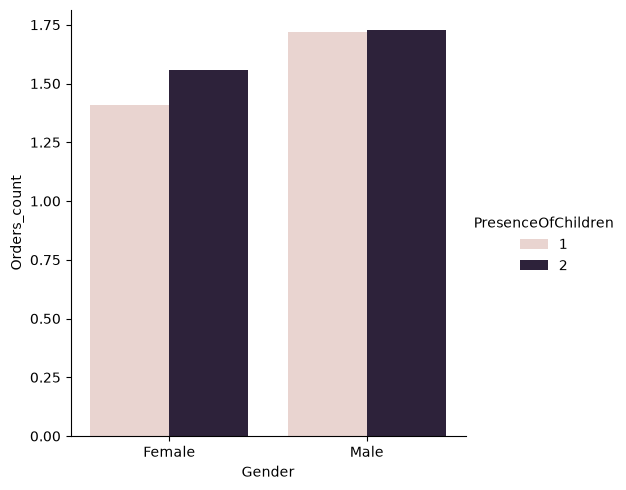

In [19]:
# Hint: Group by the dataframe via two columns (Gender and PresenceOfChildren) and find the average count of orders (Orders_count). 
mvf_data = customer.groupby(["Gender", "PresenceOfChildren"]).Orders_count.mean().reset_index()
sns.catplot(x="Gender", y="Orders_count", hue="PresenceOfChildren", data=mvf_data, kind="bar")


Write down your observation here:

-In the presence of children, fathers tend to order more than mothers. 

# Section 2: Data Preparation Decisions, Dashboard Tab, and Evaluation (55%)

In this section you make the data-preparation decisions yourself, use an AI coding assistant to build a workbench that can carry them out and show each step, and then check what it built and report what the data shows. Most of the points go to your decisions and your evaluation, not to how polished the app looks.

| Part | What | Points | Generative AI |
|---|---|---|---|
| 2A | Decide: data-preparation plan and new features | 20 | Not allowed |
| 2B | Build: update your CLAUDE.md, then build a Data Preparation Workbench with an AI assistant | 15 | Required |
| 2C | Check the app, and report what the data shows | 20 | Items 1 and 3 not allowed |

Use **titanic_train.csv** (included in this assignment folder) for all of Section 2.

## 2A. Decide (20 points, no generative AI)

Finish 2A **before** you open the AI assistant. Then commit and push with the message `Assignment 2: 2A decisions (before AI)`. Commit times are checked, so this commit must come before any AI work on the dashboard.

### 1. Data-preparation decision table (10 points)
For each issue, give your decision, one alternative you considered and rejected, and the reason, with evidence from the data (for example, a count, a percentage, or a groupby result). The code cell below the table prints evidence for each issue: run it and use what it shows. You may add your own lines.

| Issue | Your decision | Alternative you rejected | Reason and evidence |
|---|---|---|---|
| Age has missing values | | | |
| Cabin has missing values | | | |
| Embarked has missing values | | | |
| Sex, Embarked, and Pclass are categorical | | | |
| Name and Ticket are free text | | | |

**Example of one row** (Customer data from Lab 05/06, not Titanic; Lab 07 walks through this example):

| Issue | Your decision | Alternative you rejected | Reason and evidence |
|---|---|---|---|
| Reviews and Feedback_Call have missing values | First add a flag HasReview (1 if the customer left a review), then drop both columns with the Lab 05/06 rule (keep only columns with less than 80% missing) | Fill the missing ratings with the median rating | Reviews is 83.2% and Feedback_Call 83.8% missing, so filled ratings would mostly be made up. Whether a customer left a review is real information: churn is 0.750 for reviewers and 0.719 for the others. |


In [20]:
titanic = pd.read_csv("titanic_train.csv")
print(titanic.shape)

# Share of missing values in each column (as in Lab 05/06)
print(titanic.isnull().mean().round(3))

# Evidence for the Age, Embarked and categorical rows
print(titanic["Age"].describe())
print(titanic["Embarked"].value_counts())
print(titanic.groupby("Sex").Survived.mean())
print(titanic.groupby("Pclass").Survived.mean())

# Add your own lines here if you need more evidence

(891, 12)
PassengerId    0.000
Survived       0.000
Pclass         0.000
Name           0.000
Sex            0.000
Age            0.199
SibSp          0.000
Parch          0.000
Ticket         0.000
Fare           0.000
Cabin          0.771
Embarked       0.002
dtype: float64
count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64
Embarked
S    644
C    168
Q     77
Name: count, dtype: int64
Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


### 2. Feature engineering (10 points)
Building on the 9/30 in-class exercise, you work with two new features.

**Feature 1, a worked example (4 points).** The first code cell below creates **FamilySize** and checks it with a groupby. Run it, then, in the cell after it and without AI, explain in your own words what each line does, the hypothesis it tests (why might family size be related to survival?), and whether the data supports it.

**Feature 2, your own (6 points).** Create one more feature yourself by adapting the same pattern (for example from Name, Cabin or Fare). State a **hypothesis**, create the feature with pandas, check it with a groupby, and write one or two sentences on whether the data supports it.

Then save the data with both new features for 2B, with `to_csv()` from Lab 05/06: `titanic.to_csv("titanic_features.csv", index=False)`.

**Example** (Customer data, not Titanic): the feature **AgeAtJoin** = year of JoinDate minus BirthYear. Hypothesis: older customers churn less, because they may be more settled in their choices. Check with `customer.groupby("Churn").AgeAtJoin.mean()`: the average AgeAtJoin is 60.9 for returning customers and 60.4 for churned customers. The data does not support the hypothesis: the difference is about half a year.


In [ ]:
# Feature 1, worked example: FamilySize = the passenger + siblings/spouses (SibSp) + parents/children (Parch)
titanic["FamilySize"] = titanic["SibSp"] + titanic["Parch"] + 1

# Survival rate for each family size, and how many passengers have each size
print(titanic.groupby("FamilySize").Survived.mean().round(3))
print(titanic["FamilySize"].value_counts().sort_index())

Your explanation of the worked example (what each line does, the hypothesis, and what the data shows):

**Sample patterns for Feature 2** (Customer Churn data, not Titanic). Most new features follow one of the four patterns below. Run the cell to see each one, then adapt the pattern that fits your idea in the Feature 2 cell. Pattern 4, taking part of a text value, is the one most students find hardest: split the text, keep one piece, and split again.

In [ ]:
# SAMPLE (Customer Churn data, not Titanic). Each pattern creates a column, then checks it with a groupby.
customer = pd.read_csv("CustomerChurn_cleaned.csv")
customer["Churned"] = (customer["Churn"] == "NotRetained").astype(int)   # 1 = churned, so .mean() is a churn rate

# Pattern 1: a 0/1 flag from a text column
customer["EmailOK"] = (customer["FlagEmailable"] == "Y").astype(int)
print(customer.groupby("EmailOK").Churned.agg(["mean", "count"]).round(3))

# Pattern 2: a ratio of two number columns
customer["SalesPerOrder"] = customer["TotalSales_sum"] / customer["Orders_count"]
print(customer.groupby("Churned").SalesPerOrder.mean().round(1))

# Pattern 3: groups (bins) of a number column, with pd.cut
customer["SpendLevel"] = pd.cut(customer["TotalSales_sum"], bins=[0, 100, 500, 100000], labels=["low", "mid", "high"])
print(customer.groupby("SpendLevel", observed=True).Churned.agg(["mean", "count"]).round(3))

# Pattern 4: part of a text value. "2012-01-03 16:36:00": split at the space and keep piece 0 ("2012-01-03"),
# then split at "-" and keep piece 0 ("2012")
customer["JoinYear"] = customer["CustomerSinceDate"].str.split(" ").str[0].str.split("-").str[0]
print(customer.groupby("JoinYear").Churned.agg(["mean", "count"]).round(3))

In [ ]:
# Feature 2 (yours): create it and check it with a groupby, then save both features with to_csv()

Feature 2: your hypothesis and what the data shows:

## 2B. Build with an AI assistant (15 points)

### What you build
A small web app, written in Python with [Streamlit](https://streamlit.io), with one tab: a **Data Preparation Workbench**. Someone uploads a data file, applies data-preparation steps from a menu, and checks the effect of each step before and after. The decisions stay yours. The workbench carries them out and shows them, so you and anyone you share it with can check them. It makes no decisions by itself and has no AI model inside.

Use **Claude Code** with your UVA account (setup guide in the **Course Setup** module on Canvas). Start it from your **`comm4259-work`** folder. You must be able to explain every line of code in your app.

```
comm4259-work/
├── CLAUDE.md                   your course rules for Claude (Step 2)
└── assignment_02/
    ├── Assignment_02-Data_Preparation.ipynb   this notebook
    ├── titanic_train.csv, titanic_features.csv, ...
    └── dashboard/
        ├── app.py              the Streamlit app
        ├── requirements.txt    the packages the app needs
        ├── README.md           what the app does and how to run it
        ├── AI_USE_LOG.md       how you used Claude Code (you write it)
        ├── ai_sessions/        your exported Claude Code session
        └── data/               copies of the data the app reads
```

### Step 1. Get ready
In the VS Code terminal, from `comm4259-work`:
```
streamlit --version
mkdir assignment_02/dashboard
mkdir assignment_02/dashboard/data
```
Note the Streamlit version number. If `streamlit` is not found, run `pip install streamlit`, but do not upgrade Streamlit or any other package. Copy **titanic_train.csv** and your **titanic_features.csv** from 2A into `assignment_02/dashboard/data/`.

### Step 2. Update your CLAUDE.md for the whole course (2 points)
In Lab 07 you created `comm4259-work/CLAUDE.md` with rules for one lab. Claude Code reads this file at the start of every session in every folder inside `comm4259-work`, so it can hold your rules for the rest of the course: Labs 08 to 12, Assignments 2 to 5, and the project.

1. From `comm4259-work`, start Claude Code (`claude`). **Keep this one session open until you finish 2B**: do not type `/exit`, and open another terminal with the **+** in the terminal panel whenever you need one.
2. **Talk it through with the agent.** Paste this prompt, then answer each question in your own words, in full sentences:
   ```
   Read my CLAUDE.md. I want to turn it into rules for the whole course (Labs 08-12, Assignments 2-5 and the project), not only Lab 07.
   Interview me: ask me one question at a time about how I want you to work with me, for example how to explain code,
   which folders you may change, what to do when you are unsure, and what you must never do. Wait for my answer before
   the next question, and ask at most six questions. Then propose the changes to CLAUDE.md as a list, and change the
   file only after I say yes.
   ```
   Read the proposed changes and accept only the ones you agree with. When you are done, your file should include at least:
   - a short map of the course folders (`lab_NN/`, `assignment_NN/`, `project/`), and the rule that the agent only changes the folder named in your prompt;
   - the sections where it must not help: any section marked "no generative AI" (in this assignment, Section 1, 2A, 2C.1 and 2C.3);
   - that it never runs `git commit` or `git push` for you. You commit yourself, and Section 3 checks your commit times.
3. **Add your own rules by hand.** Open `CLAUDE.md` in VS Code and, without AI, add a section `## My own rules` with at least two rules in your own words. Base each one on something that happened when you worked with the agent in Lab 07 or this assignment. For example: `- Do not add tabs, charts or files I did not ask for. Suggest them to me instead.`
4. **Check it.** Your open session read the file when it started, so first tell it: *I added my own rules to CLAUDE.md. Read the file again.* Then, in the second terminal, from `comm4259-work`, run `claude -p "List the rules in my CLAUDE.md, one line each."` (a new session that reads the file fresh). Both should list your own rules.

### Step 3. Plan
In the Claude session, press **Shift+Tab** until the bottom line shows **plan mode**. Copy the prompt below, replace each `<...>` with your own text, and paste it. It follows the five-part recipe from Lab 04 and Lab 07: **Goal** (the app), **Context** (your decisions), **Constraints** (the folder, your version, no decisions by the app), **Artifacts** (the files) and **Finished** (the four things a user must be able to do).

```
Work only in assignment_02/dashboard/: create and edit files only there.
My Streamlit version is <your version>. Only use features available in that version, and do not install or upgrade any packages.
Context: these are my data-preparation decisions for data/titanic_features.csv, and the workbench must be able to carry them out:
- Age: <your decision from 2A>
- Cabin: <your decision>
- Embarked: <your decision>
- Sex, Embarked and Pclass: <your decision>
- Name and Ticket: <your decision>
Plan a Streamlit app: app.py (read the data with Path(__file__).parent / "data") with one tab, Data Preparation Workbench,
plus requirements.txt, README.md, an empty ai_sessions/ folder and an empty AI_USE_LOG.md (I write the log myself).
The workbench must let a user:
1. upload any CSV (st.file_uploader), or use data/titanic_features.csv when no file is uploaded, and see a profile:
   rows, columns, the type of each column, and the number and share of missing values in each column;
2. add steps from a fixed menu: drop a column; fill missing values (mean, median, most frequent, or a value the user types);
   dummy-code a column; drop rows that are missing a value;
3. see, for each step, the rows, columns and missing values before and after, and the pandas line the step equals,
   written the way Lab 05/06 writes it, for example df["Age"] = df["Age"].fillna(df["Age"].median());
4. download the prepared data as a CSV file.
The app makes no decisions on its own and uses no AI model. Keep the code simple enough for a beginner to read.
Ask me if anything in this plan is unclear.
```
If one of your decisions needs something the menu does not have (for example, filling Age with a different median for each Pclass), add one line asking for it. An **undo last step** button is welcome but not required.

### Step 4. Review the plan, then build
Read the plan before you approve it. Does it follow each of your decisions and your `CLAUDE.md`? Does it add anything you did not ask for? If not what you want, tell it what to change. Then approve it and let it build, reading each permission prompt before you accept it.

### Step 5. Run and fix
In the second terminal, from `comm4259-work`, run `streamlit run assignment_02/dashboard/app.py` (or `python -m streamlit run assignment_02/dashboard/app.py`). The first time, Streamlit asks for an email address; leave it blank and press Enter. If the app shows an error, copy it into the Claude terminal and ask for a fix, then click **Rerun** in the browser.

### Step 6. Export the session, once, at the end
In the Claude terminal, type `/export assignment_02/dashboard/ai_sessions/assignment_02.md`. This Claude Code command (not a prompt) writes the whole conversation to that file: the interview, the plan, the build and every fix. Open the file and check that it is all there; a summary written by the agent does not count. Then type `/exit`.

| Item | Points |
|---|---|
| The app runs from a fresh copy of your repository with `streamlit run assignment_02/dashboard/app.py` | 3 |
| The workbench does the four things listed in the prompt (profile, menu steps, before and after with the pandas line, download), and they work correctly | 6 |
| `CLAUDE.md` covers the whole course (folder map, no-AI sections, no git for you) and has `## My own rules` with at least two rules you wrote | 2 |
| The exported session is in `assignment_02/dashboard/ai_sessions/assignment_02.md` and shows the interview and the plan-mode step | 2 |
| `README.md` explains how to use the workbench and how to run the app | 2 |

**Optional bonus (up to 2 points): an EDA tab.** Only after the workbench works, ask Claude in the same session to add an **EDA** tab (`st.tabs`) that shows, for the raw or the prepared data, at least three of these, each with the pandas line it uses: summary statistics and a frequency table (`describe()`, `value_counts()`); a histogram of a chosen column; the rate of Survived for each group of a chosen column; the correlation table (`corr(numeric_only=True)`); feature weighting by information gain and chi-squared (Lecture 05).

## 2C. Check the App and Report What the Data Shows (20 points)

Write items 1 and 2 in `AI_USE_LOG.md` under a heading for Assignment 2, together with the assistant you used and how long you spent. Item 3 goes in this notebook.

1. **Check the app (8 points, no generative AI).** Upload your `titanic_features.csv` to the workbench, apply your 2A decisions as steps, and download the prepared CSV into `assignment_02/` (for example as `titanic_prepared.csv`). In your code cell below, load it with `pd.read_csv()` and recompute **two** numbers the app shows, for example the rows and columns after your steps, the missing values left in Age, or the survival rate for one value of a feature. The sample cell shows five checks on the Customer Churn data; copy the ones you need and change the file and column names. In `AI_USE_LOG.md`, write each number, what the app shows, what your code shows, and whether they match. If a number does not match, find out why. For example: "Rows after my Age decision: app 891, my code 891, match."
2. **What the AI got wrong or added, or a test you ran (4 points).** Describe one thing Claude Code got wrong or added without being asked (an extra tab, a step you did not request, a changed decision), and what you changed. If you found nothing, try to break the app and report what happened. For example: upload `CustomerChurn_cleaned.csv` instead of the Titanic file, dummy-code a column that still has missing values, or fill a text column with the mean.
3. **What the data shows (8 points, no generative AI).** Write **two findings** in plain language, as you would for a manager, one or two sentences each. Each finding must give the number that supports it and say where it comes from (the workbench, a groupby in this notebook, or the EDA tab if you built it):
   - one about one of your **2A decisions** (for example, how many passengers have exactly the same age after your Age decision),
   - one of your choice (for example, what your Feature 2 shows about survival).

In [ ]:
# SAMPLE (Customer Churn data, not Titanic): five ways to check numbers the app shows. It runs as it is.
raw = pd.read_csv("CustomerChurn_cleaned.csv")

# DEMO ONLY: these two lines stand in for the workbench. In your own cell, read the file you downloaded
# instead, for example prepared = pd.read_csv("titanic_prepared.csv")
prepared = raw.drop(columns=["CountryCode"])
prepared = pd.get_dummies(prepared, columns=["Gender"])

# Check 1: rows and columns, before and after
print("Raw:", raw.shape, "  Prepared:", prepared.shape)

# Check 2: missing values left, in total and in each column that still has some
missing = prepared.isnull().sum()
print("Missing values left:", missing.sum())
print(missing[missing > 0])

# Check 3: after a fill with the median, how many rows now hold that value
fill_value = raw["BirthYear"].median()
print("BirthYear median:", fill_value, "  rows at that value:", (prepared["BirthYear"] == fill_value).sum())

# Check 4: after dummy-coding, the new columns and how many 1s each one has
dummy_cols = [col for col in prepared.columns if col.startswith("Gender_")]
print(prepared[dummy_cols].sum())

# Check 5: the rate of the target in one group. Churn is text here, so make it 0/1 first;
# Survived is already 0/1, so for Titanic use prepared.loc[<condition>, "Survived"].mean()
churned = (prepared["Churn"] == "NotRetained").astype(int)
print("Churn rate, female customers:", round(churned[prepared["Gender_Female"] == 1].mean(), 3))

In [ ]:
# 2C.1: your check (no AI). Load the CSV you downloaded from the workbench and recompute two numbers the app shows.
raw = pd.read_csv("titanic_features.csv")
prepared = pd.read_csv("titanic_prepared.csv")   # change to the name of your downloaded file

# Number 1:

# Number 2:

**2C.3: What the data shows (no generative AI).** Your two findings, each with its number and where it comes from:
1. One of your 2A decisions:
2. Your choice:

# Section 3: GitHub Record of Your Work (10%)

Keep this assignment in your `comm4259-work` repository, the same one you push labs to.

1. **Folder.** Unzip the assignment into `comm4259-work/assignment_02/`. Dashboard work goes in `comm4259-work/assignment_02/dashboard/`.
2. **Commit as you go.** Make **at least three commits** for this assignment, spread over your work (for example after each section), each with a message that says what changed. One of them must be the 2A commit, made before you use any AI (see 2A). Run the commands from `comm4259-work`:
   ```
   git add .
   git commit -m "Assignment 2: finished Section 1"
   git push
   ```
3. **Push before the deadline.** Your last commit must be pushed before the Canvas due date. Commit times are checked.
4. **Teaching team access.** Keep `analyticsli`, `zayliet` and `jisungl` as collaborators on your repository (you added them in Assignment 1).
5. **Paste your repository link** in the Description section at the top of this notebook.

| Item | Points |
|---|---|
| At least three commits for this assignment, spread over the work, pushed before the deadline | 5 |
| Folders as described above, with the teaching team able to see the repository | 5 |